In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 59.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from Bio.Seq import Seq
from Bio import pairwise2
from Bio.pairwise2 import format_alignment

/usr/local/lib/python3.12/dist-packages/Bio/pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


[Venus Flytrap Sequence]
-> Length Before Cleaning : 1475 characters
-> Missing Values ('N')   : 0 found and dropped
-> Formatting Noise (\n)  : 22 found and dropped
-> Length After Cleaning  : 1453 bp (Pure DNA)

[Sundew Sequence]
-> Length Before Cleaning : 1246 characters
-> Missing Values ('N')   : 0 found and dropped
-> Formatting Noise (\n)  : 19 found and dropped
-> Length After Cleaning  : 1227 bp (Pure DNA)



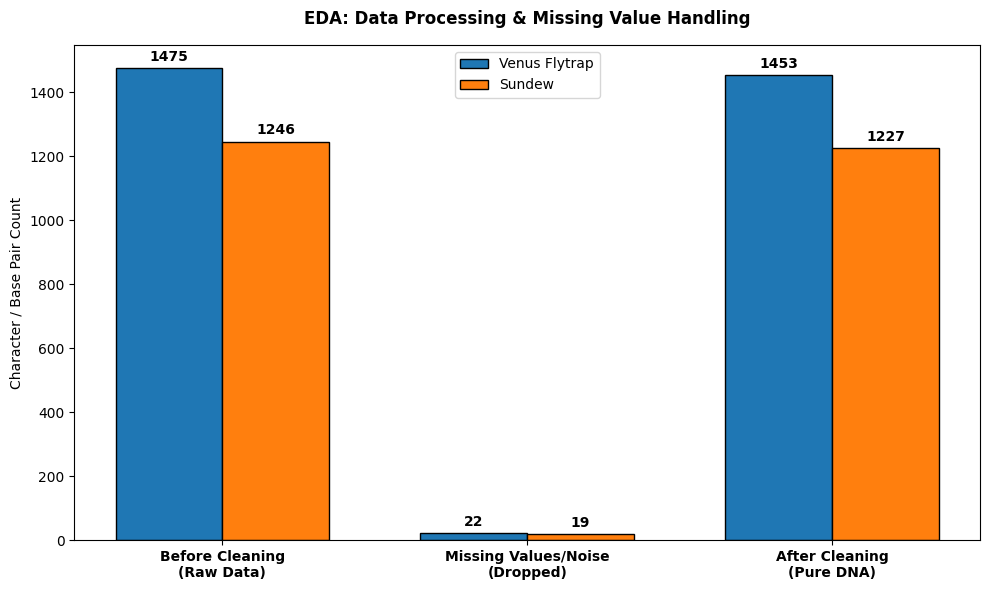

In [ ]:
# raw data
venus_raw = """
TCCTGAAGTTTCGACACGTGAAAAAAAAAACCTGGGGGCGTATCATTCAAATCATTGGGCCGGTACTGGA
TGTAGCTTTTCCACCAAGCAAGATGCCTTATATTTACAACGCTCTAGTAGTTAAAGGTCGAGATACTCTT
GGTCAACCAATTAATGTTACTTGTGAGGTACAACAATTATTAGGAAATAATCGAGTTAGAGCTGTAGCTA
TGAGTGCTACAGATGGTCTAATGAGAGGGATGGAAGTAGTTGATACAGGAGCTGCTTTAAGCGTTCCGGT
GGGCAGCGCAACTCTCGGACGAATTTTTAACGTCCTTGGGGAGCCTATTGATAATTTAGGTCCTGTAGAT
ACTCGCACAACATCTCCTATTCATAGATCTGCACCCGCCTTTATACAGTTAGAGACAAAATTGTCGATTT
TTGAAACAGGAATTAAAGTCGTAGATCTTTTAGCCCCTTATCGTCGTGGAGGAAAAATTGGACTATTTGG
GGGAGCTGGAGTGGGCAAAACAGTACTCATTATGGAATTGATCAACAACATCGCAAAAGCTCATGGGGGT
GTATCCGTATTTGCCGGAGTAGGTGAGCGTACTCGTGAAGGAAATGATCTTTACAAGGAAATGAAAGAAT
CTGGAGTTATTAATGAACAAAATATTGGAGAATCAAAAGTGGCTCTAGTATACGGCCAAATGAATGAACC
GCCGGGAGCTCGTATGAGAGTGGGTTTGACTGCCCTAACGATGGCGGAATTTTTTCGAGATGTTAATAAA
CAAGACGTACTTCTATTTATCGACAATATTTTCCGTTTCGTCCAAGCAGGATCTGAAGTATCTGCCTTAT
TGGGTCGAATGCCTTCTGCTGTCGGTTATCAACCTACTCTTAGTACCGAAATGGGTTCTTTACAAGAAAG
AATTACTTCTACCAAAGAAGGTTCCATAACTTCGATTCAAGCAGTTTATGTACCTGCAGATGATTTGACC
GACCCCGCTCCTGCCACGACATTTGCACATTTAGATGCAACTACCGTCCTATCAAGAGGATTAGCCGCCA
AAGGTATCTATCCCGCAGTAGATCCTTTAGATTCAACGTCAACTATGCTCCAACCTAAGATCGTTGGTGA
CAAACATTATGAAACTGCACAACGAGTAAAACAAACTTTACAACGTTACAAAGAAGTTCAAGACATTATA
GCTATTCTTGGATTGGACGAATTATCCGAAGAAGATCGTTTAACTGTATCCAGAGCACGCAAAATTGAGC
GTTTCTTATCACAACCCTTTGTCGTAGCAGAAGTATTTACCGGTTCCCCAGGAAAATTCGTCGGTCTCGC
AGAAACAATTAGAGGGTTTCAATTGATCCTTTCCGGAGAATTAGATGGTCTTCCTGAACAGGCCTTTTAT
TTGGTGGGTAACATCGATGAAGCTACCGAGAMAGCTATTAACTTAGAAAGGAG
"""

sundew_raw = """
TTAACTTATTATACTCCTGACTATCAAACCCTAGATACTGATATCTTGGCAGCATTCCGAGTCACCCCGC
AACCTGGAGTTCCACCAGAAGAAGCAGGAGCAGCGGTAGCTGCCGAATCTTCTACTGGTACATGGACAAC
TGTGTGGACTGATGGACTTACCAGCCTTGATCGTTACAAAGGGCGATGCTACCACATCGAGCCTGTTTCT
GGAGAAGAGAATCAATTTATTGCTTATGTAGCTTATCCATTAGACCTTTTTGAAGAAGGTTCTGTTACTA
ACATGTTTACTTCCATTGTGGGTAATGTATTTGGGTTCAAAGCTCTGCGTGCTCTACGTTTGGAGGATTT
GCGAATCCCTCCTTCTTATACAAAAACTTTCCAAGGCCCACCTCACGGTATCCAAGTTGAGAGAGATAAA
TTGAACAAATATGGTCGTCCCCTATTGGGATGTACTATTAAACCTAAATTAGGGTTATCTGCGAAGAACT
ATGGCCGAGCAGTTTATGAATGTCTTCGCGGTGGACTTGATTTTACCAAAGATGATGAAAACGTTAACTC
CCAACCATTTATGCGTTGGAGAGACCGTTTCTTATTTTGTGCAGAAGCACTTTATAAAGCCCAGGCAGAA
ACTGGTGAAATCAAAGGGCATTACTTGAATGCTACTGCCGGGACATGCGAAGAGATGATAAAAAGGGCTG
TATTTGCCAGAGAACTGGGAGTTCCTATCGTAATGCATGACTACTTAACAGGAGGATTCACCGCAAATAC
TAGCTTGGCTCAGTATTGTCGAGATAATGGACTACTTCTTCACATCCACCGTGCAATGCATGCCGTTCTT
GATAGACAGAAGAATCATGGTATACATTTCCGTGTACTAGCTAAAGCCTTACGTCTGTCTGGTGGCGATC
ATATTCATTCTGGAACCGTAGTAGGTAAACTGGAAGGGGAACGAGACATCACCTTAGGCTTCGTTGATTT
ATTACGTGATGATTTTATTGAAAAAGACAGAACTCGCGGTATTTATTTCACCCAACCTTGGGTTTCCCTA
CCAGGTGTTCTGCCCGTAGCTTCAGGGGGCATTCACGTTTGGCATATGCCCGCTCTAACCGAGATCTTTG
GGGATGATTCCGTATTACAATTCGGTGGAGGAACTTTAGGGCACCCTTGGGGAAATGCACCGGGTGCTGC
AGCGAATCGAGTAGCTCTAGAAGCATGTGTACAAGCT
"""

# processing & cleaning
def process_and_clean_sequence(raw_seq, organism_name):
    seq_upper = raw_seq.upper()

    missing_n_count = seq_upper.count('N')
    newline_count = seq_upper.count('\n')
    noise_count = missing_n_count + newline_count

    clean_seq = seq_upper.replace('\n', '').replace(' ', '').replace('N', '')

    print(f"[{organism_name} Sequence]")
    print(f"-> Length Before Cleaning : {len(raw_seq)} characters")
    print(f"-> Missing Values ('N')   : {missing_n_count} found and dropped")
    print(f"-> Formatting Noise (\\n)  : {newline_count} found and dropped")
    print(f"-> Length After Cleaning  : {len(clean_seq)} bp (Pure DNA)\n")

    return len(raw_seq), noise_count, len(clean_seq), clean_seq

raw_len_V, noise_V, clean_len_V, seq_venus = process_and_clean_sequence(venus_raw, "Venus Flytrap")
raw_len_S, noise_S, clean_len_S, seq_sundew = process_and_clean_sequence(sundew_raw, "Sundew")

categories = ['Before Cleaning\n(Raw Data)', 'Missing Values/Noise\n(Dropped)', 'After Cleaning\n(Pure DNA)']

venus_stats = [raw_len_V, noise_V, clean_len_V]
sundew_stats = [raw_len_S, noise_S, clean_len_S]

x = range(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar([pos - width/2 for pos in x], venus_stats, width, label='Venus Flytrap', color='#1f77b4', edgecolor='black')
bars2 = ax.bar([pos + width/2 for pos in x], sundew_stats, width, label='Sundew', color='#ff7f0e', edgecolor='black')

ax.set_title('EDA: Data Processing & Missing Value Handling', fontweight='bold', pad=15)
ax.set_ylabel('Character / Base Pair Count')
ax.set_xticks(list(x))
ax.set_xticklabels(categories, fontweight='bold')
ax.legend()

for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width() / 2, height), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

Venus Flytrap Base Composition
A: 438 bp (30.14%)
T: 407 bp (28.01%)
C: 283 bp (19.48%)
G: 324 bp (22.30%)

Sundew Base Composition
A: 332 bp (27.06%)
T: 350 bp (28.52%)
C: 260 bp (21.19%)
G: 285 bp (23.23%)


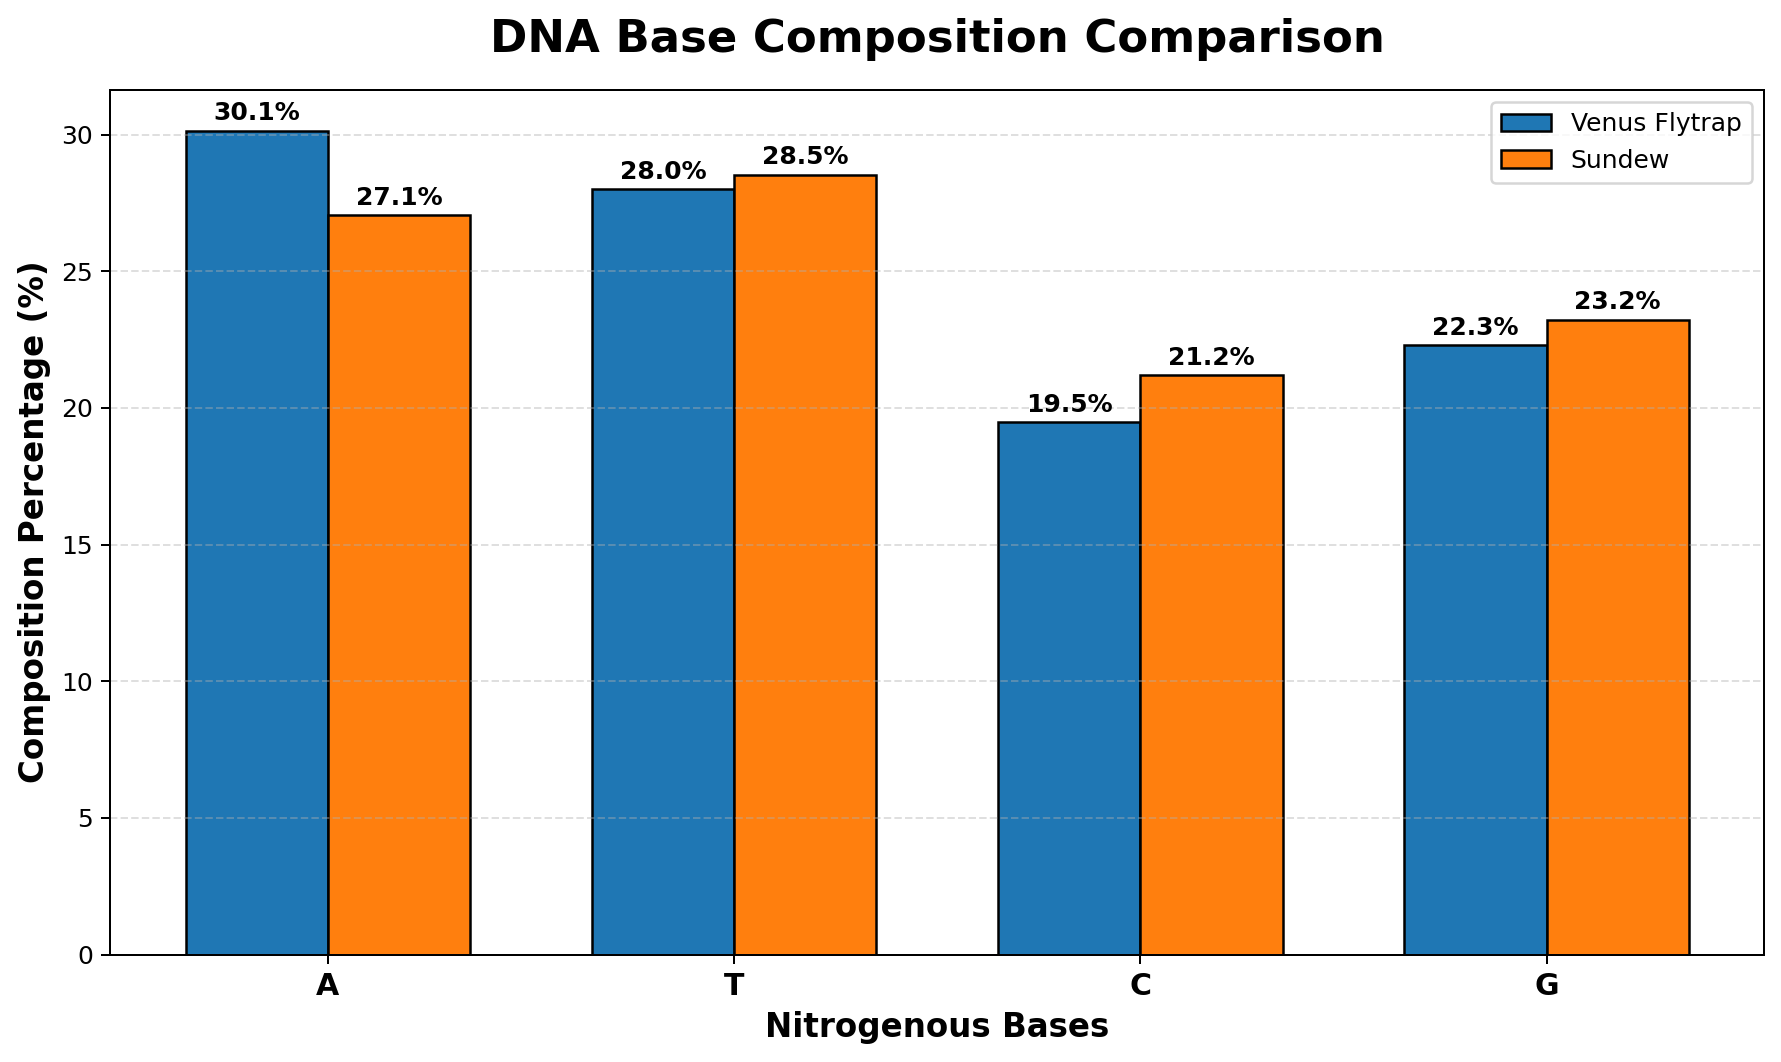

In [ ]:
bases = ['A', 'T', 'C', 'G']

venus_counts = [seq_venus.count(base) for base in bases]
sundew_counts = [seq_sundew.count(base) for base in bases]

venus_total = len(seq_venus)
sundew_total = len(seq_sundew)

venus_pct = [(count / venus_total) * 100 for count in venus_counts]
sundew_pct = [(count / sundew_total) * 100 for count in sundew_counts]

print("Venus Flytrap Base Composition")

for base, count, pct in zip(bases, venus_counts, venus_pct):
    print(f"{base}: {count} bp ({pct:.2f}%)")

print("\nSundew Base Composition")

for base, count, pct in zip(bases, sundew_counts, sundew_pct):
    print(f"{base}: {count} bp ({pct:.2f}%)")

x = range(len(bases))
width = 0.35

plt.rcParams['figure.dpi'] = 180

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar([i - width/2 for i in x], venus_pct, width, label='Venus Flytrap', color='#1f77b4', edgecolor='black')
bars2 = ax.bar([i + width/2 for i in x], sundew_pct, width, label='Sundew', color='#ff7f0e', edgecolor='black')

ax.set_title('DNA Base Composition Comparison', fontsize=18, fontweight='bold', pad=15)
ax.set_xlabel('Nitrogenous Bases', fontsize=13, fontweight='bold')

ax.set_ylabel('Composition Percentage (%)', fontsize=13, fontweight='bold')
ax.set_xticks(list(x))

ax.set_xticklabels(bases, fontsize=12, fontweight='bold')
ax.legend()

ax.grid(axis='y', linestyle='--', alpha=0.4)

for bar in bars1 + bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.2, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

Alignment Score      : 818.5
Identity Percentage  : 52.10%
Total Matches        : 833
Total Mismatches     : 248
Total Gaps           : 518


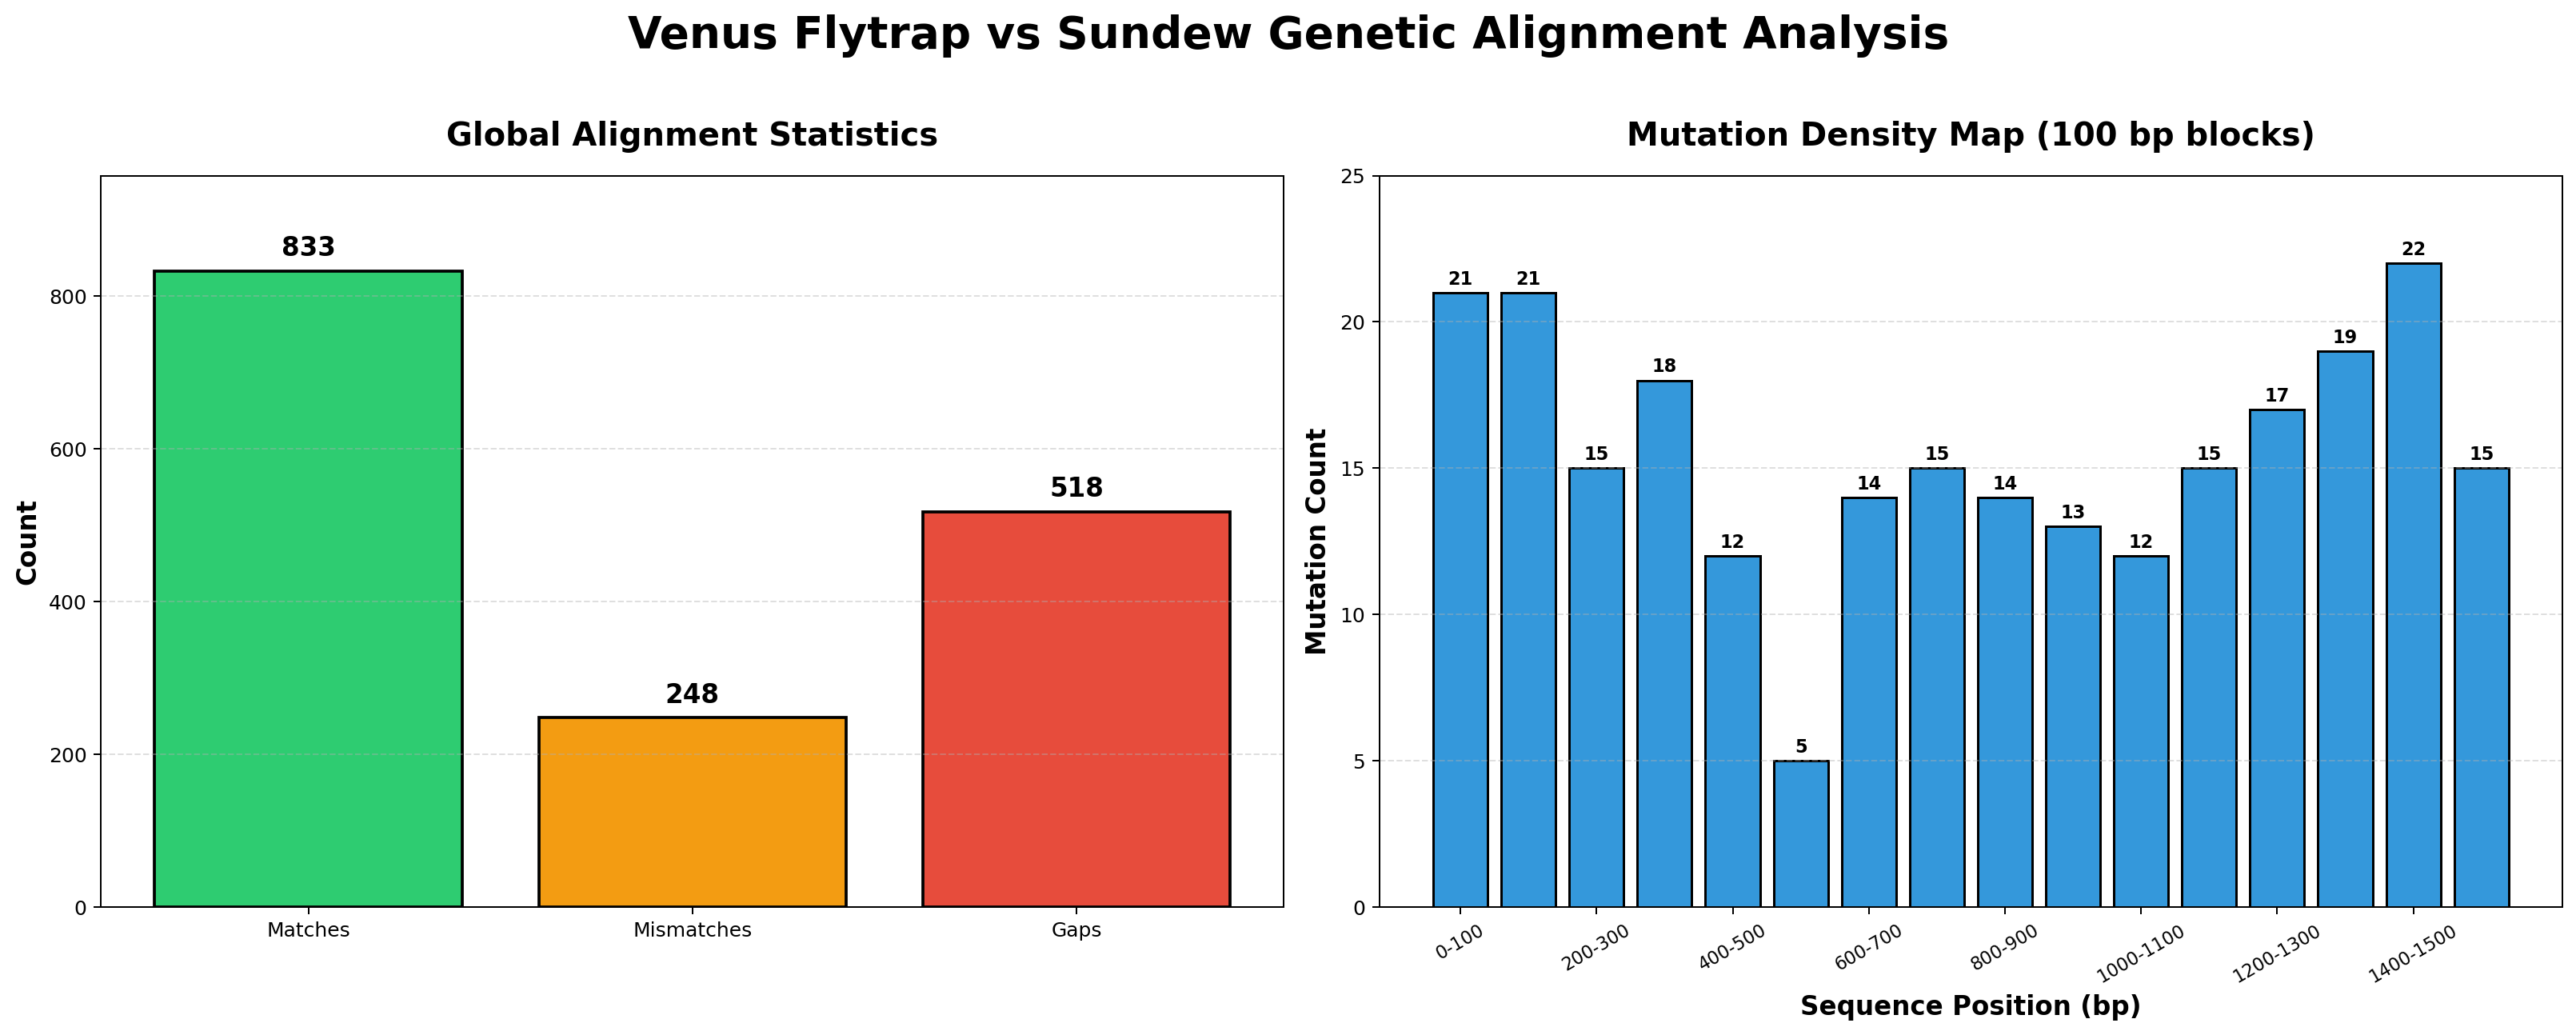

In [ ]:
global_alignments = pairwise2.align.globalms(seq_venus, seq_sundew, 2, -1, -2, -0.5)

best_global = global_alignments[0]

aln_venus = best_global.seqA
aln_sundew = best_global.seqB

matches = 0
mismatches = 0
gaps = 0
mutation_positions = []

for i, (a, b) in enumerate(zip(aln_venus, aln_sundew)):
    if a == '-' or b == '-':
        gaps += 1
    elif a == b:
        matches += 1
    else:
        mismatches += 1
        mutation_positions.append(i)

total_length = len(aln_venus)

identity_pct = (matches / total_length) * 100

print(f"Alignment Score      : {best_global.score}")
print(f"Identity Percentage  : {identity_pct:.2f}%")
print(f"Total Matches        : {matches}")
print(f"Total Mismatches     : {mismatches}")
print(f"Total Gaps           : {gaps}")

plt.rcParams['figure.dpi'] = 180
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Venus Flytrap vs Sundew Genetic Alignment Analysis', fontsize=22, fontweight='bold', y=1.02)
categories = ['Matches', 'Mismatches', 'Gaps']
values = [matches, mismatches, gaps]

bars = axes[0].bar(categories, values, color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='black', linewidth=1.5)
axes[0].set_title('Global Alignment Statistics', fontsize=16, fontweight='bold', pad=15)
axes[0].set_ylabel('Count', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].set_ylim(0, max(values) * 1.15)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, height + max(values)*0.015, f'{int(height)}', ha='center', va='bottom', fontsize=13, fontweight='bold')
chunk_size = 100
chunks = list(range(0, total_length, chunk_size))
mismatch_counts_per_chunk = []
x_labels = []

for i in chunks:
    chunk_end = min(i + chunk_size, total_length)
    mismatch_in_chunk = sum(1 for pos in mutation_positions if i <= pos < chunk_end)
    mismatch_counts_per_chunk.append(mismatch_in_chunk)
    x_labels.append(f"{i}-{chunk_end}")
bars2 = axes[1].bar(range(len(x_labels)), mismatch_counts_per_chunk, color='#3498db', edgecolor='black', linewidth=1.2)

axes[1].set_title(f'Mutation Density Map ({chunk_size} bp blocks)', fontsize=16, fontweight='bold', pad=15)
axes[1].set_xlabel('Sequence Position (bp)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Mutation Count', fontsize=13, fontweight='bold')
axes[1].set_xticks(range(0, len(x_labels), 2))
axes[1].set_xticklabels(x_labels[::2], rotation=30, fontsize=9)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

max_mutation = max(mismatch_counts_per_chunk)
axes[1].set_ylim(0, max_mutation + 3)
for bar in bars2:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.15, f'{int(height)}', ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

Smith-Waterman Score : 822.5
Identity Percentage  : 52.03%
Total Matches        : 832
Total Mismatches     : 249
Total Gaps           : 518
Motif Start Position : 3
Motif End Position   : 1596

Highly Conserved Motif:
4 TGAAGT--TTCGACACGTGAAAAAAAAAACCTGGGGGC-G-TATCATTCAAATCATTGGGCCG-GT-A--CTGGA---TGTAGCTTTTCCACC-----AAGCAAGATGC--CTTATATTTAC--AACGCT-CTAGTAGTTAAA-GGTCGA--GAT----ACTCTTGGTCA-ACCA--ATTAAT-GTTAC---TTGTGAGG-TACAACA---A---T-TAT-TAG-GAA-ATAATCGAGTTAGAGC---TGTAGCTATGAGTGCTAC-AGATGGTCTAATGAGAGGGATGGAAGTAGT-
... [Remaining Sequence Truncated] ...


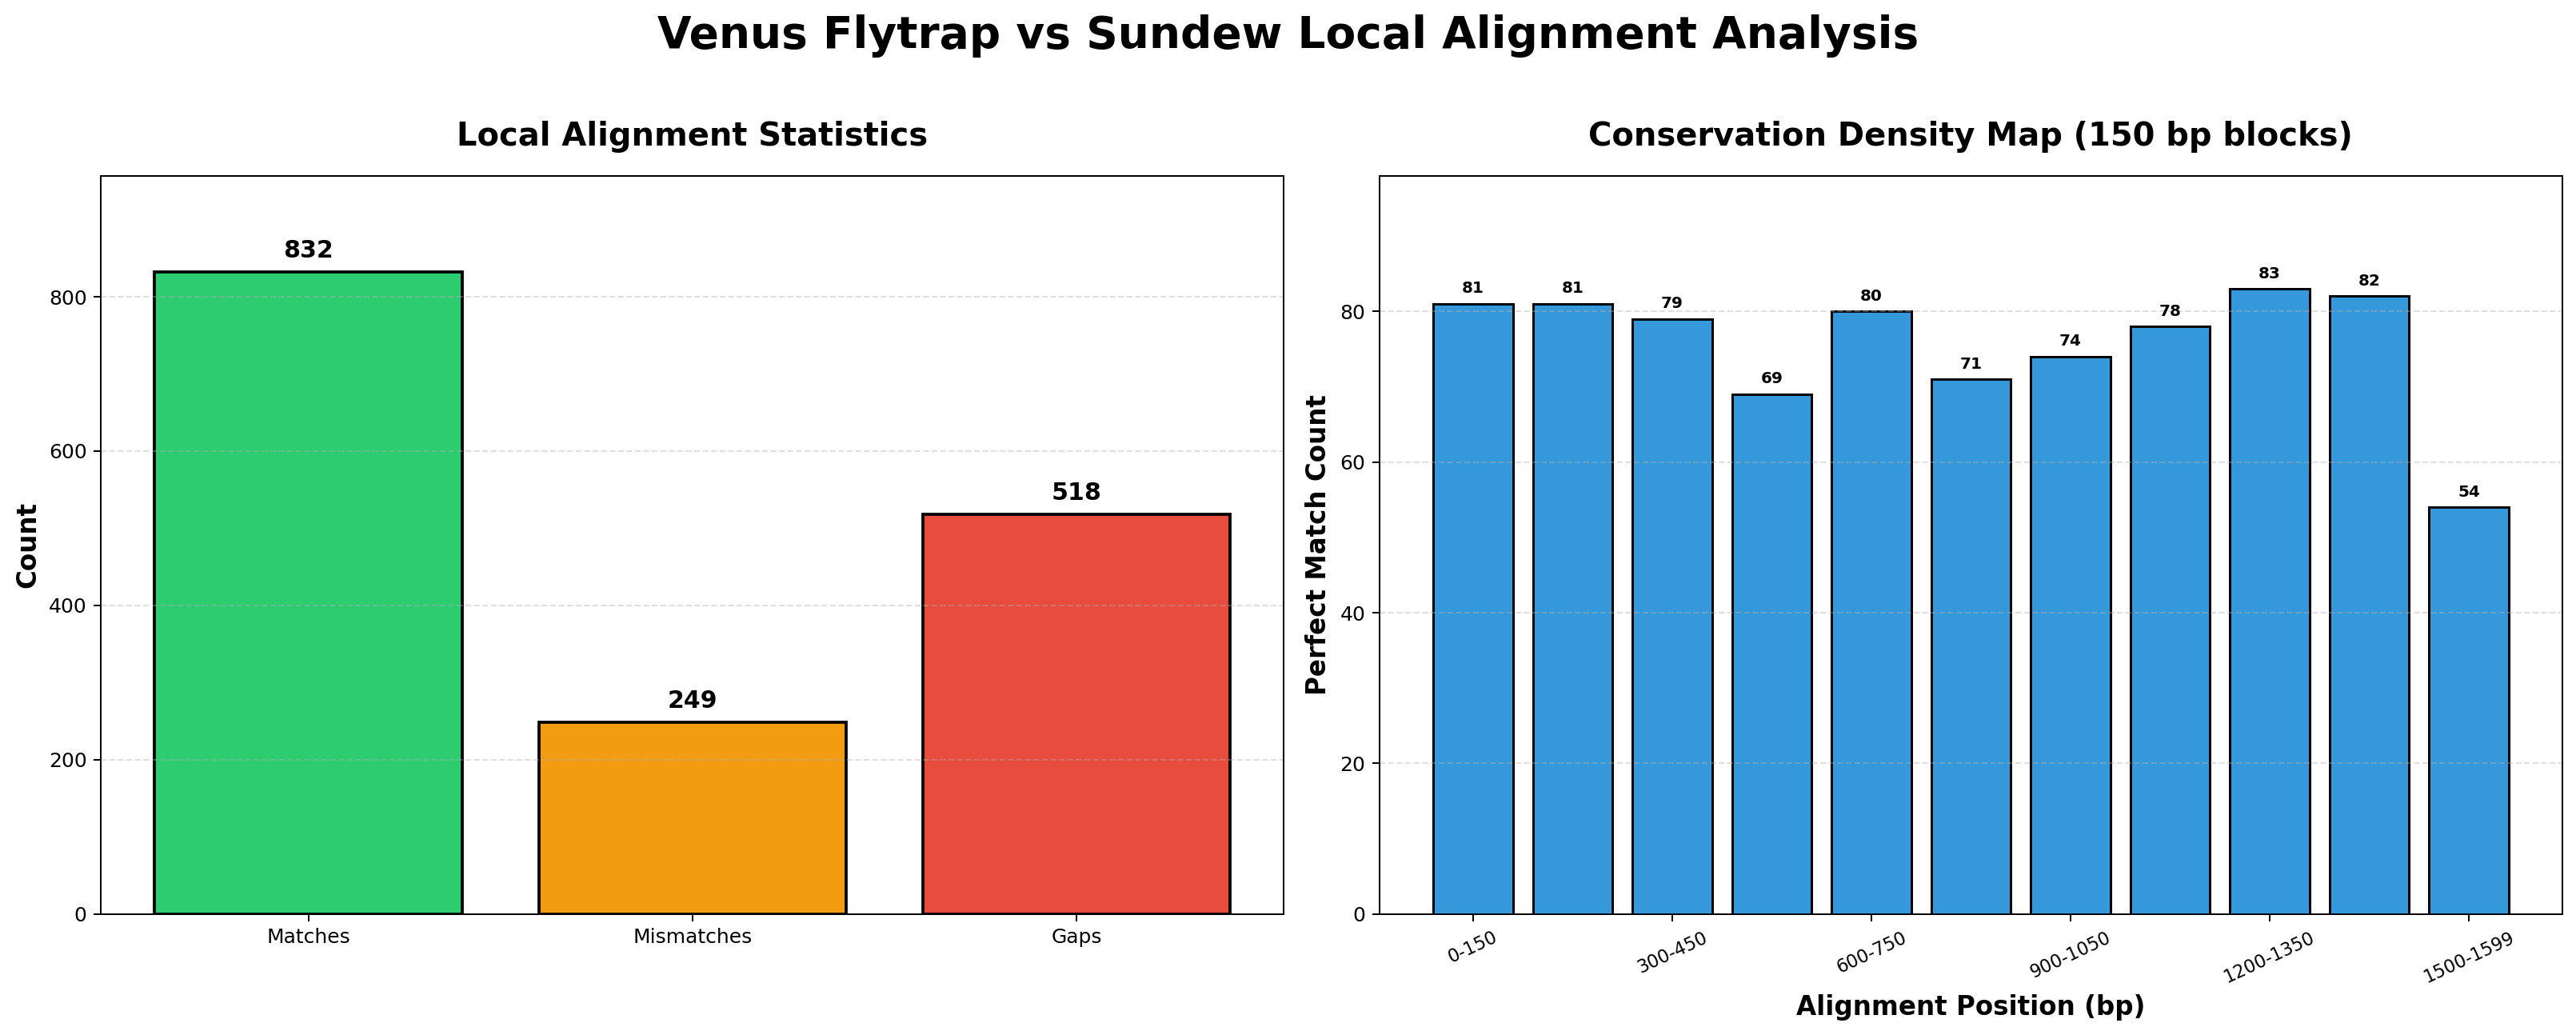

In [ ]:
local_alignments = pairwise2.align.localms(seq_venus, seq_sundew, 2, -1, -2, -0.5)
best_local = local_alignments[0]

aligned_venus = best_local.seqA
aligned_sundew = best_local.seqB

matches = 0
mismatches = 0
gaps = 0

match_positions = []
mismatch_positions = []

for i, (a, b) in enumerate(zip(aligned_venus, aligned_sundew)):
    if a == '-' or b == '-':
        gaps += 1
    elif a == b:
        matches += 1
        match_positions.append(i)
    else:
        mismatches += 1
        mismatch_positions.append(i)
alignment_length = len(aligned_venus)

identity_pct = (matches / alignment_length) * 100

print(f"Smith-Waterman Score : {best_local.score}")
print(f"Identity Percentage  : {identity_pct:.2f}%")
print(f"Total Matches        : {matches}")
print(f"Total Mismatches     : {mismatches}")
print(f"Total Gaps           : {gaps}")
print(f"Motif Start Position : {best_local.start}")
print(f"Motif End Position   : {best_local.end}\n")

print("Highly Conserved Motif:")

print(format_alignment(*best_local)[:300] + "\n... [Remaining Sequence Truncated] ...")

plt.rcParams['figure.dpi'] = 180
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Venus Flytrap vs Sundew Local Alignment Analysis', fontsize=22, fontweight='bold', y=1.02)
categories = ['Matches', 'Mismatches', 'Gaps']
values = [matches, mismatches, gaps]

bars = axes[0].bar(categories, values, color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='black', linewidth=1.5)
axes[0].set_title('Local Alignment Statistics', fontsize=16, fontweight='bold', pad=15)
axes[0].set_ylabel('Count', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].set_ylim(0, max(values) * 1.15)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, height + max(values)*0.015, f'{int(height)}', ha='center', va='bottom', fontsize=12, fontweight='bold')
chunk_size = 150
chunks = list(range(0, alignment_length, chunk_size))
match_counts_per_chunk = []
x_labels = []

for i in chunks:
    chunk_end = min(i + chunk_size, alignment_length)
    matches_in_chunk = sum(1 for pos in match_positions if i <= pos < chunk_end)
    match_counts_per_chunk.append(matches_in_chunk)
    x_labels.append(f"{i}-{chunk_end}")
bars2 = axes[1].bar(range(len(x_labels)), match_counts_per_chunk, color='#3498db', edgecolor='black', linewidth=1.2)

axes[1].set_title(f'Conservation Density Map ({chunk_size} bp blocks)', fontsize=16, fontweight='bold', pad=15)
axes[1].set_xlabel('Alignment Position (bp)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Perfect Match Count', fontsize=13, fontweight='bold')
axes[1].set_xticks(range(0, len(x_labels), 2))
axes[1].set_xticklabels(x_labels[::2], rotation=25, fontsize=9)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].set_ylim(0, max(match_counts_per_chunk) + 15)

for bar in bars2:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 1, f'{int(height)}', ha='center', va='bottom', fontsize=8, fontweight='bold')
plt.tight_layout()
plt.show()